# 02 — ABC-XYZ Demand Segmentation
**Question:** which products drive revenue, and how predictable is their demand?

Treating all 100 products the same wastes money. **ABC** ranks products by revenue contribution. **XYZ** ranks them by demand variability.
Together they tell us which products deserve tight, high-service inventory control and which should be managed loosely or made to order.

| Class | Rule used here |
|---|---|
| **A** | Products making up the first 80% of revenue |
| **B** | The next 15% (80–95%) |
| **C** | The last 5% |
| **X** | Weekly demand CV ≤ 0.5 (stable) |
| **Y** | 0.5 < CV ≤ 1.0 (variable) |
| **Z** | CV > 1.0 (erratic) |

*CV (coefficient of variation) = standard deviation ÷ mean of weekly units sold. It is measured over each product's own selling life (first to last sale), so a product launched mid-way isn't penalised for weeks before it existed.*

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import chart_style as cs
cs.apply()

df = pd.read_csv('../data/processed/order_lines_clean.csv', parse_dates=['order_date'])
m = df[(df.in_model_window == 1) & (df.is_cancelled == 0)].copy()   # Jan 2015 – Sep 2017, shipped orders only
print(f'{len(m):,} order lines | {m.product_id.nunique()} products')

164,572 order lines | 100 products


## 1. Weekly demand per product

In [2]:
m['week'] = m['order_date'].dt.to_period('W')
weekly = m.groupby(['product_id', 'week'])['order_item_quantity'].sum()

rows = []
for pid, s in weekly.groupby(level=0):
    s = s.droplevel(0)
    life = pd.period_range(s.index.min(), s.index.max(), freq='W')     # selling life
    s = s.reindex(life, fill_value=0)                                  # weeks with no sales = 0
    rows.append({'product_id': pid, 'weeks_on_sale': len(life), 'avg_weekly_units': s.mean(),
                 'sd_weekly_units': s.std(ddof=1) if len(s) > 1 else np.nan,
                 'pct_weeks_with_sales': (s > 0).mean()})
demand = pd.DataFrame(rows).set_index('product_id')
demand['cv'] = demand['sd_weekly_units'] / demand['avg_weekly_units']
demand.describe().round(2)

,weeks_on_sale,avg_weekly_units,sd_weekly_units,pct_weeks_with_sales,cv
count,100.00,100.00,96.00,100.00,96.00
mean,74.30,28.19,6.22,0.95,0.57
std,55.34,80.65,7.98,0.05,0.21
min,1.00,2.00,1.00,0.85,0.09
25%,20.00,6.34,2.52,0.91,0.48
50%,120.00,7.04,4.92,0.95,0.64
75%,121.00,9.10,5.38,1.00,0.71
max,144.00,489.27,43.97,1.00,0.97


## 2. ABC — revenue concentration

In [3]:
prod = m.groupby('product_id').agg(product_name=('product_name', 'first'), category=('category_name', 'first'),
                                    revenue=('sales', 'sum'), profit=('order_item_profit', 'sum'),
                                    units=('order_item_quantity', 'sum'))
prod = prod.sort_values('revenue', ascending=False)
prod['rev_share'] = prod['revenue'] / prod['revenue'].sum()
prod['cum_share'] = prod['rev_share'].cumsum()
prior = prod['cum_share'] - prod['rev_share']          # share BEFORE this product is added
prod['abc'] = np.select([prior < 0.80, prior < 0.95], ['A', 'B'], 'C')
prod['rank'] = range(1, len(prod) + 1)
prod.groupby('abc').agg(products=('revenue', 'size'), revenue=('revenue', 'sum'), rev_share=('rev_share', 'sum')).round(3)

,products,revenue,rev_share
abc,,,
A,7,27034447.41,0.825
B,5,4150870.00,0.127
C,88,1602931.69,0.049


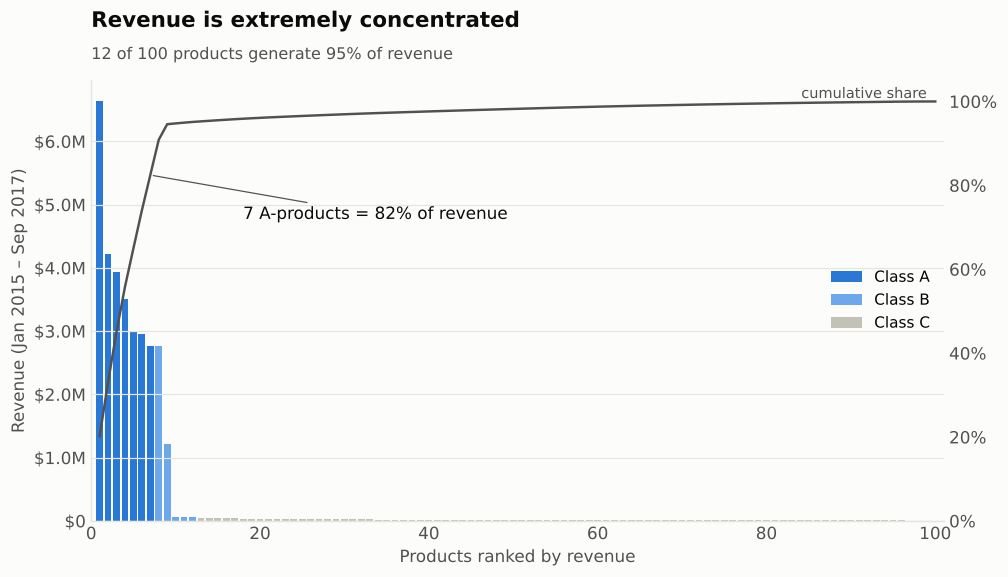

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.2))
colors = prod['abc'].map({'A': cs.BLUE, 'B': cs.BLUE_RAMP[2], 'C': cs.GREY})
ax.bar(prod['rank'], prod['revenue'], color=colors, width=0.8)
ax.yaxis.set_major_formatter(cs.money_fmt)
ax.set_xlabel('Products ranked by revenue'); ax.set_ylabel('Revenue (Jan 2015 – Sep 2017)')
ax.set_xlim(0, len(prod) + 1); ax.grid(axis='x', visible=False)

ax2 = ax.twinx()   # cumulative share on a 0–100% reference scale (a Pareto curve, not a second measure)
ax2.plot(prod['rank'], prod['cum_share'], color=cs.INK_2, lw=1.6)
ax2.yaxis.set_major_formatter(cs.pct_fmt); ax2.set_ylim(0, 1.05); ax2.grid(False)
ax2.spines[['top', 'right']].set_visible(False); ax2.tick_params(colors=cs.INK_2)

nA, nB = (prod.abc == 'A').sum(), (prod.abc == 'B').sum()
shA = prod.loc[prod.abc == 'A', 'rev_share'].sum()
ax2.annotate(f'{nA} A-products = {shA:.0%} of revenue', xy=(nA, prod.cum_share.iloc[nA - 1]), xytext=(18, 0.72),
             color=cs.INK, fontsize=11, arrowprops=dict(arrowstyle='-', color=cs.INK_2, lw=0.8))
ax2.text(len(prod) - 1, 1.0, 'cumulative share', ha='right', va='bottom', color=cs.INK_2, fontsize=9.5)
for lab, col in [('A', cs.BLUE), ('B', cs.BLUE_RAMP[2]), ('C', cs.GREY)]:
    ax.bar(0, 0, color=col, label=f'Class {lab}')
ax.legend(loc='center right')
cs.titles(ax, 'Revenue is extremely concentrated', f'{nA + nB} of 100 products generate 95% of revenue')
plt.savefig('../images/01_pareto_abc.png'); plt.show()

**Finding:** demand is far more concentrated than the classic 80/20. Seven products bring in about 82% of revenue, and the bottom 88 products together bring in about 5%.

## 3. XYZ — demand predictability

In [5]:
seg = prod.join(demand)
MIN_WEEKS = 26     # need ~6 months of history for a trustworthy variability estimate
seg['enough_history'] = seg['weeks_on_sale'] >= MIN_WEEKS
seg['xyz'] = np.select([seg.cv <= 0.5, seg.cv <= 1.0], ['X', 'Y'], 'Z')   # CV missing (sold in 1 week only) -> Z
seg['segment'] = seg['abc'] + seg['xyz']
print('Products with < 26 weeks of sales history:', (~seg.enough_history).sum())
seg.loc[~seg.enough_history, ['product_name', 'weeks_on_sale', 'revenue']].sort_values('revenue', ascending=False).head(8)

Products with < 26 weeks of sales history: 46


,product_name,weeks_on_sale,revenue
product_id,,,
724,LIJA Women's Mid-Length Panel Golf Shorts,21,22000.00
646,Merrell Women's Grassbow Sport Hiking Shoe,22,20697.93
359,Nike Men's Free TR 5.0 TB Training Shoe,20,19898.01
258,Nike Women's Free 5.0 TR FIT PRT 4 Training S,20,18903.01
251,Brooks Women's Ghost 6 Running Shoe,20,18627.93
607,Garmin Approach S3 Golf GPS Watch,20,18499.26
677,TaylorMade White Smoke IN-12 Putter,20,18498.15
24,Elevation Training Mask 2.0,21,18397.70


These short-life products (launched just before the catalog change, or tested briefly) are kept in the segmentation, but they get no statistical stock policy in notebook 03.

In [6]:
matrix_n   = pd.crosstab(seg.abc, seg.xyz).reindex(index=list('ABC'), columns=list('XYZ'), fill_value=0)
matrix_rev = seg.pivot_table(index='abc', columns='xyz', values='rev_share', aggfunc='sum').reindex(index=list('ABC'), columns=list('XYZ')).fillna(0)
display(matrix_n); display(matrix_rev.round(3))

xyz,X,Y,Z
abc,,,
A,7,0,0
B,2,3,0
C,17,67,4


xyz,X,Y,Z
abc,,,
A,0.825,0.000,0.000
B,0.121,0.005,0.000
C,0.006,0.042,0.001


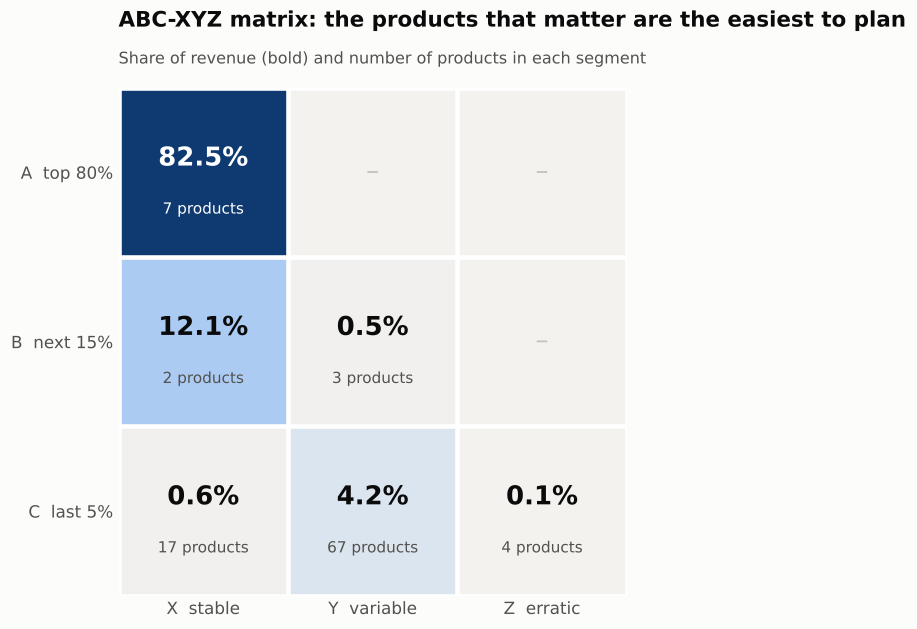

In [7]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('seq', ['#f3f2ee'] + cs.BLUE_RAMP[1:])
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.imshow(matrix_rev.values, cmap=cmap, vmin=0, vmax=0.85)
ax.set_xticks(range(3), ['X  stable', 'Y  variable', 'Z  erratic']); ax.set_yticks(range(3), ['A  top 80%', 'B  next 15%', 'C  last 5%'])
ax.grid(False); ax.spines[:].set_visible(False)
for i, a in enumerate('ABC'):
    for j, x in enumerate('XYZ'):
        v, n = matrix_rev.loc[a, x], matrix_n.loc[a, x]
        if n == 0:
            ax.text(j, i, '–', ha='center', va='center', fontsize=17, color=cs.GREY); continue
        txt_col = 'white' if v > 0.4 else cs.INK
        ax.text(j, i - 0.08, f'{v:.1%}', ha='center', va='center', fontsize=17, fontweight='bold', color=txt_col)
        ax.text(j, i + 0.22, f'{n} products', ha='center', va='center', fontsize=10, color=txt_col if v > 0.4 else cs.INK_2)
for k in range(4):
    ax.axhline(k - 0.5, color='white', lw=3); ax.axvline(k - 0.5, color='white', lw=3)
cs.titles(ax, 'ABC-XYZ matrix: the products that matter are the easiest to plan', 'Share of revenue (bold) and number of products in each segment')
plt.savefig('../images/02_abc_xyz_matrix.png'); plt.show()

**Findings**
- **All 7 A-products are X (stable):** weekly demand varies only about 10% around the mean. These products can run on a **statistical reorder point with a high service level** and *little* safety stock.
- **The long tail is Y:** most C-products sell only a few units a week and vary 50–100% week to week. Holding generous stock for them ties up cash for about 5% of revenue.
- Nothing in the A class is erratic, which is unusual and good news: the products that matter most are the easiest to plan.

## 4. Recommended policy by segment

In [8]:
policy = pd.DataFrame({
    'segment': ['AX', 'BX', 'BY', 'CX', 'CY / CZ'],
    'approach': ['Continuous review, statistical reorder point', 'Continuous review, statistical reorder point',
                 'Periodic review (weekly), statistical safety stock', 'Periodic review (bi-weekly), lean safety stock',
                 'Minimal stock or make-to-order; review for delisting'],
    'target_service_level': ['98%', '95%', '95%', '90%', '90% / case by case'],
})
policy

,segment,approach,target_service_level
0,AX,"Continuous review, statistical reorder point",98%
1,BX,"Continuous review, statistical reorder point",95%
2,BY,"Periodic review (weekly), statistical safety s...",95%
3,CX,"Periodic review (bi-weekly), lean safety stock",90%
4,CY / CZ,Minimal stock or make-to-order; review for del...,90% / case by case


In [9]:
out = seg.reset_index()[['product_id', 'product_name', 'category', 'revenue', 'profit', 'units', 'rev_share', 'cum_share',
                         'abc', 'weeks_on_sale', 'avg_weekly_units', 'sd_weekly_units', 'cv', 'xyz', 'segment', 'enough_history']]
import os; os.makedirs('../results', exist_ok=True)
out.round(4).to_csv('../results/product_segments.csv', index=False)
out.head(12).round(2)

,product_id,product_name,category,revenue,profit,units,rev_share,cum_share,abc,weeks_on_sale,avg_weekly_units,sd_weekly_units,cv,xyz,segment,enough_history
0,1004,Field & Stream Sportsman 16 Gun Fire Safe,Fishing,6631668.40,730159.12,16580,0.20,0.20,A,144,115.14,12.00,0.10,X,AX,True
1,365,Perfect Fitness Perfect Rip Deck,Cleats,4226595.45,472867.79,70455,0.13,0.33,A,144,489.27,43.78,0.09,X,AX,True
2,957,Diamondback Women's Serene Classic Comfort Bi,Camping & Hiking,3942337.16,409215.24,13142,0.12,0.45,A,144,91.26,8.68,0.10,X,AX,True
3,191,Nike Men's Free 5.0+ Running Shoe,Cardio Equipment,3501149.85,358365.13,35015,0.11,0.56,A,144,243.16,29.82,0.12,X,AX,True
4,502,Nike Men's Dri-FIT Victory Golf Polo,Women's Apparel,3007700.00,334162.57,60154,0.09,0.65,A,144,417.74,43.82,0.10,X,AX,True
5,1073,Pelican Sunstream 100 Kayak,Water Sports,2962851.85,307522.80,14815,0.09,0.74,A,144,102.88,11.36,0.11,X,AX,True
6,1014,O'Brien Men's Neoprene Life Vest,Indoor/Outdoor Games,2762144.70,302190.73,55265,0.08,0.82,A,144,383.78,43.97,0.11,X,AX,True
7,403,Nike Men's CJ Elite 2 TD Football Cleat,Men's Footwear,2760077.67,296357.12,21233,0.08,0.91,B,144,147.45,15.61,0.11,X,BX,True
8,627,Under Armour Girls' Toddler Spine Surge Runni,Shop By Sport,1213896.45,121568.96,30355,0.04,0.95,B,144,210.80,28.15,0.13,X,BX,True
9,565,adidas Youth Germany Black/Red Away Match Soc,Girls' Apparel,63490.00,7468.00,907,0.00,0.95,B,121,7.50,5.17,0.69,Y,BY,True


**Output:** `results/product_segments.csv`, which feeds notebook 03 and the Power BI / Excel models.